<a href="https://colab.research.google.com/github/ropitz/urban_ag_stl/blob/main/urban_ag_suitability_tornado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Urban Agriculture Suitability — City of St. Louis

**Purpose.** Identify and rank vacant parcels in the City of St. Louis for urban
agriculture potential using live open data.

**Method.** For every LRA-listed vacant parcel we derive a 0-100 suitability
score from four weighted layers:

| Criterion | Weight | Source | What we prefer |
|-----------|:------:|--------|----------------|
| Vacant / underutilized land | 0.30 | LRA Inventory CSV × Assessor parcel polygons (HANDLE join) | Parcel is on the LRA inventory; larger lots score higher |
| Soil contamination risk | 0.25 | EPA ACRES brownfields (point layer) | Distance to nearest brownfield — farther is better |
| Sunlight exposure proxy | 0.20 | OpenStreetMap buildings via Overpass | Lower surrounding building footprint fraction within 30 m |
| Food-access need | 0.25 | USDA FARA 2019 + Census TIGER tracts | Parcel lies in a low-income / low-access tract |

Scores are min–max normalised per criterion to [0, 1], combined with the weights
above, and multiplied by 100 for display.

**Outputs.** An interactive Folium map (`urban_ag_with_tornado_overlay_map.html`) and a
GeoJSON of the scored parcels (`urban_ag_suitability_stl_parcels.geojson`).

**Caveats.**
- The suitability score is a screening tool, not a site-fitness guarantee. High-
  ranking parcels still need soil testing, water-access confirmation, zoning
  review, and community engagement.
- The sunlight proxy uses building footprint density, not a true solar-radiation
  model — it under-weights tall-tree shading and over-weights low density.
- EPA ACRES captures *grantee-reported* brownfields only; unreported
  contamination is not visible here.


> **2025 tornado overlay added.** This combined notebook also overlays the path and damage waypoints from the May 16, 2025 EF-3 tornado on top of the suitability layer — see the *Tornado overlay* section below the imports.

In [ ]:
import json, os, time, math, io, zipfile, warnings
from pathlib import Path
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely.geometry import shape, Point, Polygon, box
import folium
from folium.plugins import MarkerCluster, Fullscreen, MeasureControl

warnings.filterwarnings("ignore")

OUT_DIR = Path("./outputs")
OUT_DIR.mkdir(exist_ok=True)

# CRS used throughout
CRS_WGS84 = "EPSG:4326"     # mapping / web
CRS_METRIC = "EPSG:26915"   # UTM 15N — accurate metres for STL

# Scoring weights (must sum to 1.0)
WEIGHTS = {
    "vacant":   0.30,
    "soil":     0.25,
    "sunlight": 0.20,
    "food":     0.25,
}
assert abs(sum(WEIGHTS.values()) - 1.0) < 1e-9

# TG brand colours (used for UI chrome only)
TG = {
    "brown": "#3b1e1c", "ivory": "#f4f4eb", "periwinkle": "#80a0d8",
    "red": "#ff4f2c",   "lightblue": "#a7d0dc", "green": "#cff29e",
}

# Max parcels to score — sampling cap for runtime. Raise to None for all.
MAX_PARCELS = 3000

# Timeouts / retries for external services
HTTP_TIMEOUT = 60

# Global configuration choices based on user request
LRA_SOURCE_URL = "https://drive.google.com/file/d/1C_1GON_c6MhHIVSHX196kHo71sR1Cf96/view?usp=sharing"
BASEMAP_STYLE = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}"
BASEMAP_ATTRIBUTION = "Tiles &copy; Esri &mdash; Esri, DeLCO, NAVTEQ, TomTom, Intermap, iPC, USGS, FAO, NPS, NRCAN, GeoBase, Kadaster NL, Ordnance Survey, Esri Japan, METI, Esri China (Hong Kong), and the GIS User Community"

print("setup complete")

setup complete


---

## Tornado overlay — May 16, 2025 EF-3 St. Louis tornado

Adds three tornado-event layers on top of the urban-ag suitability map so you
can see which high-suitability LRA parcels sit inside or adjacent to the
storm-damaged corridor. Layers are togglable in the layer-control:

| Layer | Source | Notes |
|---|---|---|
| **Tornado path (EF rating)** | NWS LSX damage survey + EWGCOG path map | Centerline digitized from the survey narrative; segments colored by EF rating. |
| **Notable damage landmarks** | NWS LSX, AP, KSDK, KMOV, STLPR, Fox 2 | ~15 curated points (e.g. Centennial Christian Church, Fontbonne, Greater Ville townhomes); each popup links to Street View / Google Satellite / Bing Bird's-eye / USGS NAIP. |
| **NOAA DAT waypoints (live)** | NOAA Damage Assessment Toolkit FeatureServer | ~700 NWS-surveyed waypoints fetched at run-time. Falls back gracefully if the service is unreachable. |

Free to view; no API keys or paid imagery required. Sub-meter post-event
satellite (Maxar, Planet, BlackSky, Capella) and Nearmap aerial **are**
available for this event but require licensing — they are not embedded.


In [ ]:
# ----------------------------------------------------------------------
# 2025 St. Louis tornado — data + helper to overlay on any folium map
# ----------------------------------------------------------------------
import json as _tornado_json, sys as _tornado_sys, urllib.parse as _tornado_urllib
from urllib.request import Request as _TornadoRequest, urlopen as _tornado_urlopen

# NWS-derived path centerline (digitized from LSX survey + EWGCOG map).
# 23.3 mi total, max 1,750 yd wide, peak 152 mph (EF-3).
TORNADO_PATH = [
    (38.6403, -90.3536),  # Touchdown — Clayton, just east of I-170 (2:39 pm CDT)
    (38.6378, -90.3477),  # Clayton — apartments, homes
    (38.6376, -90.3402),  # Fontbonne University
    (38.6394, -90.3300),  # Wydown / Skinker
    (38.6406, -90.2935),  # Forest Park north edge
    (38.6526, -90.2780),  # DeBaliviere Place — EF2
    (38.6517, -90.2680),  # Central West End / Academy
    (38.6530, -90.2563),  # Fountain Park (EF3)
    (38.6552, -90.2493),  # Lewis Place / Kingsway East
    (38.6645, -90.2391),  # Greater Ville — peak EF3
    (38.6722, -90.2220),  # Natural Bridge Ave
    (38.6776, -90.2129),  # O'Fallon neighborhood / Fairground Park
    (38.6863, -90.2050),  # North Riverfront — BNSF rail yard
    (38.6938, -90.1888),  # Crosses Mississippi River
    (38.7148, -90.1490),  # Granite City, IL
    (38.7261, -90.1131),  # Pontoon Beach, IL
    (38.7561, -90.0560),  # Glen Carbon, IL
    (38.7869, -89.9985),  # Dissipation — east of IL-157, near SIUE
]

EF_SEGMENTS = [
    (0, 1, "EF2", "Touchdown in Clayton — apartment building roof damage"),
    (1, 2, "EF1", "Clayton — apartments, homes, low-rise damage"),
    (2, 3, "EF1", "Fontbonne University campus + EF2 power-pole snap"),
    (3, 4, "EF1", "Wydown/Skinker — tree damage"),
    (4, 5, "EF2", "Forest Park edge → DeBaliviere Place — apartments destroyed"),
    (5, 6, "EF2", "Central West End / Academy — homes, churches, mid-rises"),
    (6, 7, "EF3", "Fountain Park — strip mall + brick townhomes destroyed"),
    (7, 8, "EF2", "Lewis Place / Kingsway East — Centennial Christian Church collapse"),
    (8, 9, "EF3", "Greater Ville — peak intensity, N. Newstead townhomes flattened"),
    (9, 10, "EF2", "Natural Bridge Ave — flagpole + brick townhomes"),
    (10, 11, "EF2", "O\'Fallon neighborhood / O\'Fallon Park"),
    (11, 12, "EF1", "North Riverfront — warehouses + BNSF rail yard"),
    (12, 13, "EF1", "Crossing Mississippi River into Madison County, IL"),
    (13, 14, "EF1", "Granite City, IL"),
    (14, 15, "EF1", "Pontoon Beach, IL"),
    (15, 16, "EF1", "Glen Carbon, IL — storage facility"),
    (16, 17, "EF0", "Weakening / dissipation near IL-157, SIUE"),
]

EF_COLORS = {
    "EF0": "#fde68a", "EF1": "#fbbf24", "EF2": "#f97316", "EF3": "#dc2626",
    "EF4": "#7f1d1d", "EF5": "#581c87", "EFU": "#6b7280",
    "TSTM/Wind": "#3b82f6", "Wind": "#3b82f6",
}

LANDMARKS = [
    {"name": "Centennial Christian Church", "lat": 38.6552, "lon": -90.2493, "ef": "EF2",
     "summary": "Partial collapse; 1 fatality (Patricia Ann Penelton).",
     "address": "4950 Fountain Ave, St. Louis, MO 63113"},
    {"name": "Fontbonne University", "lat": 38.6376, "lon": -90.3402, "ef": "EF1/EF2",
     "summary": "Multiple buildings damaged, EF2 power-pole snap on campus.",
     "address": "6800 Wydown Blvd, St. Louis, MO 63105"},
    {"name": "Saint Louis Zoo (RFD wind damage)", "lat": 38.6353, "lon": -90.2911, "ef": "RFD",
     "summary": "Tornado missed the zoo; rear-flank-downdraft winds damaged butterfly enclosure.",
     "address": "1 Government Dr, St. Louis, MO 63110"},
    {"name": "Forest Park (tree damage)", "lat": 38.6390, "lon": -90.2840, "ef": "EF1",
     "summary": "Widespread tree damage across the north side of the park.",
     "address": "Forest Park, St. Louis, MO"},
    {"name": "MetroLink — DeBaliviere → Brentwood I-64", "lat": 38.6486, "lon": -90.2851, "ef": "EF1/EF2",
     "summary": "Overhead catenary damaged; service disrupted.",
     "address": "Forest Park–DeBaliviere station"},
    {"name": "DeBaliviere Place — apartments destroyed", "lat": 38.6526, "lon": -90.2780, "ef": "EF2",
     "summary": "Two apartment buildings received high-end EF2 damage.",
     "address": "DeBaliviere Pl, St. Louis, MO 63112"},
    {"name": "Central West End — mid-rise damage", "lat": 38.6488, "lon": -90.2624, "ef": "EF1/EF2",
     "summary": "Homes, churches, mid-rise buildings, traffic lights damaged.",
     "address": "Central West End, St. Louis, MO"},
    {"name": "Fountain Park strip mall (destroyed)", "lat": 38.6541, "lon": -90.2553, "ef": "EF3",
     "summary": "Strip mall partially destroyed; brick townhouse flattened (low-end EF3).",
     "address": "Aldine Ave & Newstead Ave"},
    {"name": "N. Newstead Ave brick townhouses", "lat": 38.6657, "lon": -90.2391, "ef": "EF3",
     "summary": "Multiple brick townhouses flattened — peak intensity.",
     "address": "N. Newstead Ave, St. Louis, MO 63113"},
    {"name": "O\'Fallon Park townhomes", "lat": 38.6776, "lon": -90.2129, "ef": "EF2",
     "summary": "Townhouses collapsed at O\'Fallon Park; church steeple knocked off nearby.",
     "address": "O\'Fallon Park, St. Louis, MO"},
    {"name": "Harlem Tap Room (RFD collapse)", "lat": 38.6682, "lon": -90.2200, "ef": "RFD",
     "summary": "Bar collapsed (20 inside, no fatalities). Outside the tornado path — likely RFD.",
     "address": "Natural Bridge Ave area"},
    {"name": "BNSF rail yard / warehouses (North Riverfront)", "lat": 38.6863, "lon": -90.2050, "ef": "EF1/EF2",
     "summary": "Industrial warehouses damaged; wooden power poles snapped (EF2).",
     "address": "N. Riverfront industrial area"},
    {"name": "Granite City, IL", "lat": 38.7148, "lon": -90.1490, "ef": "EF1",
     "summary": "Homes damaged, trees, businesses, medical center hit.",
     "address": "Granite City, IL 62040"},
    {"name": "Pontoon Beach, IL", "lat": 38.7261, "lon": -90.1131, "ef": "EF1",
     "summary": "Trees and homes damaged.", "address": "Pontoon Beach, IL 62040"},
    {"name": "Glen Carbon, IL — storage facility", "lat": 38.7561, "lon": -90.0560, "ef": "EF1",
     "summary": "Storage facility and trees damaged.", "address": "Glen Carbon, IL 62034"},
]

EVENT_DATE = "2025-05-16"
NWS_OFFICE = "LSX"
TORNADO_BBOX = (-90.40, 38.55, -89.95, 38.81)  # (W, S, E, N)
DAT_BASE = ("https://services.dat.noaa.gov/arcgis/rest/services/"
            "nws_damageassessmenttoolkit/DamageViewer/FeatureServer/0/query")

def _streetview_url(lat, lon):
    return f"https://www.google.com/maps/@?api=1&map_action=pano&viewpoint={lat},{lon}"
def _gsat_url(lat, lon, z=19):
    return f"https://www.google.com/maps/@{lat},{lon},{z}z/data=!3m1!1e3"
def _bing_url(lat, lon):
    return f"https://www.bing.com/maps?cp={lat}~{lon}&style=o&lvl=19"
def _usgs_url(lat, lon):
    return f"https://earthexplorer.usgs.gov/?coordinates={lat:.5f},{lon:.5f}&datasetSearch=naip"

def fetch_dat_points(timeout=30):
    """Pull NOAA DAT waypoints for the May 16, 2025 STL tornado. Returns []
    on any failure so the rest of the notebook keeps working offline."""
    where = (
        f"office=\'{NWS_OFFICE}\' AND "
        f"stormdate>=DATE \'{EVENT_DATE}\' AND "
        f"stormdate<=DATE \'2025-05-17\'"
    )
    params = {
        "where": where,
        "geometry": ",".join(map(str, TORNADO_BBOX)),
        "geometryType": "esriGeometryEnvelope",
        "inSR": "4326",
        "spatialRel": "esriSpatialRelIntersects",
        "outFields": "*",
        "returnGeometry": "true",
        "f": "geojson",
        "resultRecordCount": "2000",
    }
    url = DAT_BASE + "?" + _tornado_urllib.urlencode(params)
    try:
        req = _TornadoRequest(url, headers={"User-Agent": "stl-tornado-overlay/1.0"})
        with _tornado_urlopen(req, timeout=timeout) as resp:
            data = _tornado_json.loads(resp.read().decode("utf-8"))
        return data.get("features", []) or []
    except Exception as exc:
        print(f"[tornado] live DAT fetch failed ({exc!r}); using curated layers only",
              file=_tornado_sys.stderr)
        return []

# Cache the live DAT result so we hit the service only once even if both maps
# are rebuilt during a session.
_DAT_CACHE = {"features": None}
def _get_dat_features():
    if _DAT_CACHE["features"] is None:
        feats = fetch_dat_points()
        _DAT_CACHE["features"] = feats
        print(f"[tornado] {len(feats)} NOAA DAT waypoints loaded")
    return _DAT_CACHE["features"]

def add_tornado_layers(fmap, *, include_dat=True):
    """Add tornado-event layers to an existing folium.Map.

    Adds three FeatureGroups (toggleable via the existing LayerControl):
      1. Tornado path (EF rating) — color-coded polylines.
      2. Notable damage landmarks — circles with rich popups + Street View links.
      3. NOAA DAT waypoints (live) — every NWS-surveyed point.

    Call this BEFORE folium.LayerControl(...).add_to(fmap).
    """
    # 1. Path segments
    seg_layer = folium.FeatureGroup(name="Tornado path (May 16, 2025 EF-3)", show=True)
    for s, e, ef, note in EF_SEGMENTS:
        coords = TORNADO_PATH[s:e+1]
        folium.PolyLine(
            locations=coords, color=EF_COLORS.get(ef, "#666"),
            weight=6, opacity=0.85,
            tooltip=f"{ef} — {note}",
            popup=folium.Popup(f"<b>{ef}</b><br>{note}", max_width=320),
        ).add_to(seg_layer)
    # Touchdown / dissipation pins
    folium.Marker(
        location=TORNADO_PATH[0],
        tooltip="Touchdown 2:39 pm CDT — Clayton, MO",
        icon=folium.Icon(color="darkred", icon="play", prefix="fa"),
        popup=folium.Popup("<b>Touchdown</b><br>2:39 pm CDT, May 16, 2025<br>Clayton, MO",
                           max_width=300),
    ).add_to(seg_layer)
    folium.Marker(
        location=TORNADO_PATH[-1],
        tooltip="Dissipation 3:06 pm CDT — east of IL-157, near SIUE",
        icon=folium.Icon(color="black", icon="stop", prefix="fa"),
        popup=folium.Popup("<b>Dissipation</b><br>3:06 pm CDT, near SIUE Edwardsville",
                           max_width=300),
    ).add_to(seg_layer)
    seg_layer.add_to(fmap)

    # 2. Curated landmarks
    lm_layer = folium.FeatureGroup(name="Tornado damage landmarks", show=True)
    for lm in LANDMARKS:
        name = lm["name"]
        ef_label = lm["ef"]
        address = lm["address"]
        summary = lm["summary"]
        ck = ef_label.split("/")[0]
        color = EF_COLORS.get(ck if ck in EF_COLORS else "EF1", "#999")
        sv = _streetview_url(lm["lat"], lm["lon"])
        gs = _gsat_url(lm["lat"], lm["lon"])
        bm = _bing_url(lm["lat"], lm["lon"])
        ee = _usgs_url(lm["lat"], lm["lon"])
        html = (
            "<div style=\"font-family:system-ui;font-size:13px;max-width:340px;\">"
            f"<div style=\"font-weight:600;font-size:14px;margin-bottom:4px;\">{name}</div>"
            f"<div style=\"color:#666;margin-bottom:6px;\">"
            f"<span style=\"display:inline-block;padding:1px 6px;border-radius:4px;"
            f"background:{color};color:white;font-size:11px;margin-right:6px;\">{ef_label}</span>"
            f"{address}</div>"
            f"<div style=\"margin-bottom:8px;\">{summary}</div>"
            f"<div style=\"display:flex;flex-wrap:wrap;gap:6px;\">"
            f"<a href=\"{sv}\" target=\"_blank\">Street View</a>"
            f"<a href=\"{gs}\" target=\"_blank\">Google Sat</a>"
            f"<a href=\"{bm}\" target=\"_blank\">Bing Bird&apos;s-eye</a>"
            f"<a href=\"{ee}\" target=\"_blank\">USGS NAIP</a>"
            f"</div></div>"
        )
        folium.CircleMarker(
            location=(lm["lat"], lm["lon"]), radius=8,
            color="black", weight=1, fill=True,
            fill_color=color, fill_opacity=0.9,
            tooltip=f"{name} — {ef_label}",
            popup=folium.Popup(html, max_width=360),
        ).add_to(lm_layer)
    lm_layer.add_to(fmap)

    # 3. Live NOAA DAT waypoints
    if include_dat:
        dat_layer = folium.FeatureGroup(name="NOAA DAT waypoints (live)", show=False)
        for feat in _get_dat_features():
            geom = feat.get("geometry") or {}
            if geom.get("type") != "Point":
                continue
            coords = geom.get("coordinates") or [None, None]
            lon, lat = coords[0], coords[1]
            if lat is None or lon is None:
                continue
            p = feat.get("properties", {})
            ef = (p.get("efscale") or "").strip() or "EFU"
            damage_txt = (p.get("damage_txt") or "").strip()
            dod_txt = (p.get("dod_txt") or "").strip()
            windspeed = p.get("windspeed") or ""
            comments = (p.get("comments") or "").strip()
            sv = _streetview_url(lat, lon); gs = _gsat_url(lat, lon)
            html = (
                "<div style='font-family:system-ui;font-size:12px;max-width:300px;'>"
                f"<div><b>{ef}</b> &middot; {windspeed} mph</div>"
                f"<div>{damage_txt}</div>"
                f"<div style='color:#555;'>{dod_txt}</div>"
                f"<div style='color:#555;margin-top:4px;'>{comments[:240]}</div>"
                f"<div style='margin-top:6px;'>"
                f"<a href=\'{sv}\' target=\'_blank\'>Street View</a> &middot; "
                f"<a href=\'{gs}\' target=\'_blank\'>Satellite</a></div></div>"
            )
            folium.CircleMarker(
                location=(lat, lon), radius=3,
                color=EF_COLORS.get(ef, "#777"), weight=1, fill=True,
                fill_color=EF_COLORS.get(ef, "#777"), fill_opacity=0.9,
                tooltip=f"DAT: {ef} {damage_txt}",
                popup=folium.Popup(html, max_width=320),
            ).add_to(dat_layer)
        dat_layer.add_to(fmap)
    return fmap

print("tornado overlay loaded — call add_tornado_layers(m) before LayerControl")


tornado overlay loaded — call add_tornado_layers(m) before LayerControl


In [ ]:
# -----------------------------------------------------------------
# Helper: paginated ArcGIS REST query -> GeoDataFrame
# -----------------------------------------------------------------
def arcgis_query(url, where="1=1", out_fields="*", geometry=None,
                 geometry_type="esriGeometryEnvelope", in_sr=4326,
                 page_size=1000, max_records=None):
    '''Return a GeoDataFrame from an ArcGIS MapServer/FeatureServer layer.

    Handles pagination via resultOffset / resultRecordCount.
    '''
    features = []
    offset = 0
    params_base = {
        "where": where,
        "outFields": out_fields,
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson",
        "resultRecordCount": page_size,
    }
    if geometry is not None:
        params_base.update({
            "geometry": json.dumps(geometry),
            "geometryType": geometry_type,
            "inSR": in_sr,
            "spatialRel": "esriSpatialRelIntersects",
        })
    while True:
        params = dict(params_base, resultOffset=offset)
        r = requests.get(url + "/query", params=params, timeout=HTTP_TIMEOUT)
        r.raise_for_status()
        js = r.json()
        batch = js.get("features", [])
        if not batch:
            break
        features.extend(batch)
        if len(batch) < page_size:
            break
        offset += page_size
        if max_records and len(features) >= max_records:
            features = features[:max_records]
            break
        time.sleep(0.2)
    if not features:
        return gpd.GeoDataFrame(geometry=[], crs=CRS_WGS84)
    gdf = gpd.GeoDataFrame.from_features(features, crs=CRS_WGS84)
    return gdf

# -----------------------------------------------------------------
# Helper: min-max normalise to [0,1] (robust to constant columns)
# -----------------------------------------------------------------
def minmax(series, invert=False):
    s = series.astype(float)
    lo, hi = s.min(), s.max()
    if hi - lo < 1e-9:
        return pd.Series(0.5, index=s.index)
    n = (s - lo) / (hi - lo)
    return 1 - n if invert else n


## 1. City of St. Louis boundary

We pull the city boundary from the Census Bureau TIGERweb service (St. Louis City is FIPS county `29510`).

City polygon area (km²): 171.5


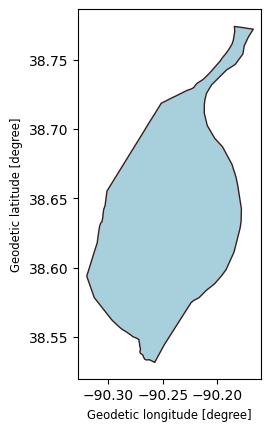

In [ ]:
TIGER_PLACES = (
    "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/"
    "MapServer/13"  # Counties (current)
)
city = arcgis_query(
    TIGER_PLACES,
    where="GEOID='29510'",           # St. Louis City (independent city)
    out_fields="NAME,STATE,GEOID",
)
assert not city.empty, "Failed to fetch St. Louis city boundary"
city_geom_wgs = city.unary_union
city_bbox = city.total_bounds   # (minx, miny, maxx, maxy) lon/lat
print("City polygon area (km²):",
      round(city.to_crs(CRS_METRIC).area.iloc[0] / 1e6, 1))
city.plot(facecolor=TG['lightblue'], edgecolor=TG['brown']);


## 2. LRA vacant parcels

We combine two public sources:

1. **LRA Inventory CSV** (nightly, St. Louis Development Corporation) — all LRA-owned parcels with their integer `HANDLE` identifier, acquisition date, status, and usage.
2. **City Assessor parcels MapServer** — polygon geometry for every parcel in the city, keyed by `HANDLE`.

We download the CSV, filter to active (non-sold, non-retired) records, then query the Assessor layer for the matching `HANDLE`s in batches.

In [ ]:
# --- 2a. LRA inventory (nightly CSV / Custom Drive URL) ---
# Using the requested Google Drive URL for loading the parcel layer dataset
import gdown

drive_id = "1C_1GON_c6MhHIVSHX196kHo71sR1Cf96"
local_lra_csv = OUT_DIR / "LRA_INVENTORY.csv"

print(f"Downloading local LRA parcel dataset from Google Drive to {local_lra_csv}...")
gdown.download(id=drive_id, output=str(local_lra_csv), quiet=False)

lra_inv = pd.read_csv(local_lra_csv)
print("LRA inventory rows:", len(lra_inv))
print("columns:", list(lra_inv.columns))
lra_inv["HANDLE"] = pd.to_numeric(lra_inv["ParcelId"], errors="coerce")
lra_inv = lra_inv.dropna(subset=["HANDLE"]).copy()
lra_inv["HANDLE"] = lra_inv["HANDLE"].astype(int)
# Drop duplicates on HANDLE (keep first)
lra_inv = lra_inv.drop_duplicates(subset=["HANDLE"])
print(f"Unique HANDLE values after cleanup: {len(lra_inv):,}")
lra_inv.head(3)

Downloading...
From: https://drive.google.com/uc?id=1C_1GON_c6MhHIVSHX196kHo71sR1Cf96
To: /content/outputs/LRA_INVENTORY.csv
100%|██████████| 2.91M/2.91M [00:00<00:00, 82.3MB/s]


LRA inventory rows: 10368
columns: ['ParcelId', 'Parcel_Status', 'Usage', 'ENTERED_DATE', 'ACQUISITION_DATE', 'Property_Source', 'AddrNum', 'StPreDir', 'StName', 'StType', 'StSufDir', 'Address', 'WARD', 'NeighborhoodNumber', 'NeighborhoodName', 'LowAddrNum', 'LowAddrSuf', 'HighAddrNum', 'HighAddrSuf', 'Description', 'Class', 'LegalDescription', 'PropertyType', 'Side lot Eligible?', 'Stories', 'Irregular_Lot', 'Frontage', 'NbrOfUnits', 'SQFT']
Unique HANDLE values after cleanup: 10,365


,ParcelId,Parcel_Status,Usage,ENTERED_DATE,ACQUISITION_DATE,Property_Source,AddrNum,StPreDir,StName,StType,...,Class,LegalDescription,PropertyType,Side lot Eligible?,Stories,Irregular_Lot,Frontage,NbrOfUnits,SQFT,HANDLE
0,23849040000,Available,"Vacant Lot,Vacant Lot",NaN,Wed Aug 18 2010 19:00:00 GMT-0500 (Central Day...,Tax Suit,3734,NaN,MAFFITT,AV,...,A,C.B. 2384 MAFFITT AVE25 FT X 140 FTJACKSON ADD...,Lot,NaN,0.0,NaN,NaN,NaN,3520,23849040000
1,35879610000,Available,"Vacant Lot,Vacant Lot",NaN,Tue Mar 19 1985 18:00:00 GMT-0600 (Central Sta...,Tax Suit,3909,NaN,SHERMAN,PL,...,A,C B 3587 SHERMAN PL25 FT X 110 FTHULLS EST ADD...,Lot,NaN,0.0,NaN,NaN,NaN,2751,35879610000
2,53209060000,Available,"Vacant Lot,Vacant Lot",NaN,Wed Nov 16 2016 18:00:00 GMT-0600 (Central Sta...,Tax Suit,4924,NaN,GENEVIEVE,AV,...,C,CB 5320 GENEVIEVE AVE30 X 125WESTFIELD PK ADDN...,Lot,NaN,0.0,NaN,NaN,NaN,3759,53209060000


In [ ]:
# --- 2b. Discover the parcel polygon layer on the Assessor MapServer ---
ASSESSOR_SVC = ("https://maps8.stlouis-mo.gov/arcgis/rest/services/"
                "ASSESSOR/Assessor_Public_Parcels/MapServer")
meta = requests.get(ASSESSOR_SVC, params={"f": "json"},
                    timeout=HTTP_TIMEOUT).json()
assessor_layers = [(l['id'], l['name']) for l in meta.get('layers', [])]
print("Assessor MapServer layers:", assessor_layers)

# Pick the first layer whose name contains 'parcel'
parcel_layer_id = next(
    (lid for lid, name in assessor_layers if 'parcel' in name.lower()),
    assessor_layers[0][0] if assessor_layers else 0,
)
PARCELS_URL = f"{ASSESSOR_SVC}/{parcel_layer_id}"

# Confirm the parcel layer has a ParcelId field, as LRA inventory uses ParcelId.
layer_meta = requests.get(PARCELS_URL, params={"f": "json"},
                          timeout=HTTP_TIMEOUT).json()
field_names = [f['name'] for f in layer_meta.get('fields', [])]
print(f"Parcel layer id={parcel_layer_id}: {layer_meta.get('name')}")
print("sample fields:", field_names[:12], "..." if len(field_names) > 12 else "")
assert any(fn.upper() == 'PARCELID' for fn in field_names), (
    "Assessor layer has no ParcelId field — inspect `field_names` and adjust "
    "the join key below")
HANDLE_FIELD = next(fn for fn in field_names if fn.upper() == 'PARCELID')
print("join field:", HANDLE_FIELD)


Assessor MapServer layers: [(0, 'Dimension Lines'), (1, 'Easement Lines'), (2, 'Leasehold Improvement'), (3, 'Railroad'), (4, 'Wharf'), (5, 'Streets'), (6, 'Air Rights'), (7, 'Vacated Ordinance'), (8, 'Sub Rights'), (9, 'Buildings'), (10, 'Condos'), (11, 'Parcels'), (12, 'Lots'), (13, 'Subdivision'), (14, 'City Block'), (15, 'City Boundary')]
Parcel layer id=11: Parcels
sample fields: ['OBJECTID', 'ParcelId', 'CityBlock', 'Parcel', 'OwnerCode', 'ColParcelId', 'ColCityBlock', 'ColParcel', 'PrimAddrRecNum', 'AddrType', 'LowAddrNum', 'LowAddrSuf'] ...
join field: ParcelId


In [ ]:
# --- 2c. Query polygons for the LRA HANDLEs, in batches ---
# Sample the inventory down to MAX_PARCELS to keep runtime bounded.
handles = lra_inv["HANDLE"].tolist()
if MAX_PARCELS is not None and len(handles) > MAX_PARCELS:
    handles = list(np.random.default_rng(7).choice(handles, MAX_PARCELS,
                                                   replace=False))
    handles = [int(h) for h in handles]

BATCH = 400   # ArcGIS max URL length safe batch
frames = []
for i in range(0, len(handles), BATCH):
    chunk = handles[i:i+BATCH]
    # Quote string HANDLEs for the ArcGIS string field 'ParcelId'
    in_list_quoted = ",".join(f"'{str(h)}'" for h in chunk)
    where = f"{HANDLE_FIELD} IN ({in_list_quoted})"
    gdf = arcgis_query(PARCELS_URL, where=where,
                       out_fields=f"{HANDLE_FIELD}", page_size=1000)
    if not gdf.empty:
        gdf = gdf.rename(columns={HANDLE_FIELD: "HANDLE"})
        frames.append(gdf)
    print(f"  batch {i//BATCH + 1}/{(len(handles)-1)//BATCH + 1}: "
          f"{len(gdf)} polygons returned")

lra = (pd.concat(frames, ignore_index=True)
       if frames else gpd.GeoDataFrame(columns=["HANDLE","geometry"],
                                       geometry="geometry", crs=CRS_WGS84))
lra = gpd.GeoDataFrame(lra, geometry="geometry", crs=CRS_WGS84)
lra = lra[lra.geometry.notna() & ~lra.geometry.is_empty].copy()
lra["HANDLE"] = pd.to_numeric(lra["HANDLE"], errors="coerce").astype("Int64")

# Merge the inventory attributes back onto the polygons
lra = lra.merge(lra_inv[["HANDLE","Parcel_Status","Usage",
                          "ACQUISITION_DATE","Property_Source"]],
                on="HANDLE", how="left")

# Reproject to metric CRS for area / distance calculations
lra = lra.to_crs(CRS_METRIC)
lra["area_sqm"] = lra.geometry.area
lra = lra[lra["area_sqm"] > 50].reset_index(drop=True)
print(f"Final LRA parcels with geometry: {len(lra):,} "
      f"(median size {lra['area_sqm'].median():.0f} m²)")


  batch 1/8: 393 polygons returned
  batch 2/8: 398 polygons returned
  batch 3/8: 398 polygons returned
  batch 4/8: 393 polygons returned
  batch 5/8: 398 polygons returned
  batch 6/8: 398 polygons returned
  batch 7/8: 394 polygons returned
  batch 8/8: 198 polygons returned
Final LRA parcels with geometry: 2,949 (median size 348 m²)


## 3. EPA brownfields (ACRES)

Grantee-reported brownfield sites in the EPA Assessment, Cleanup and Redevelopment Exchange System. We query within the city bounding box.

In [ ]:
EPA_BROWN = ("https://geopub.epa.gov/arcgis/rest/services/"
             "EMEF/efpoints/MapServer/5")

minx, miny, maxx, maxy = city_bbox
env = {"xmin": minx, "ymin": miny, "xmax": maxx, "ymax": maxy,
       "spatialReference": {"wkid": 4326}}
brown = arcgis_query(EPA_BROWN, where="1=1", out_fields="*",
                     geometry=env, geometry_type="esriGeometryEnvelope",
                     in_sr=4326)
# keep only points inside the city polygon
if not brown.empty:
    brown = brown[brown.intersects(city_geom_wgs)].copy()
print(f"Brownfield points in STL city: {len(brown)}")
brown.head(3) if not brown.empty else "none"


Brownfield points in STL city: 394


,geometry,OBJECTID,registry_id,primary_name,location_address,city_name,county_name,state_code,epa_region,postal_code,latitude,longitude,pgm_sys_acrnm,pgm_sys_id,fips_code,huc_code,facility_url
1,POINT (-90.19227 38.67304),1207,110009293905,GREAT LAKES CONTAINER CORPORATION,42 FERRY STREET,ST. LOUIS,SAINT LOUIS CITY,MO,Region 07,63147,38.67304,-90.19227,ACRES,14056,,,https://ofmpub.epa.gov/apex/cimc/f?p=CIMC:31::...
2,POINT (-90.28046 38.67864),1794,110015333600,KENNERLY AVE REDEVELOPMENT,5901 KENNERLY,ST. LOUIS,SAINT LOUIS CITY,MO,Region 07,63120,38.67864,-90.28046,ACRES,10985,,,https://ofmpub.epa.gov/apex/cimc/f?p=CIMC:31::...
3,POINT (-90.18178 38.63663),1796,110015333628,THE FRESH BUILDING,10 ASHLEY STREET,ST. LOUIS,SAINT LOUIS CITY,MO,Region 07,63102,38.63663,-90.18178,ACRES,10989,,,https://ofmpub.epa.gov/apex/cimc/f?p=CIMC:31::...


## 4. USDA food-access tracts

FARA 2019 flags census tracts that are both low-income and low-access (`LILATracts_Vehicle` = 1, the vehicle-access definition used by USDA). We join it to Census tract polygons.

In [ ]:
# --- FARA 2019 spreadsheet ---
FARA_XLSX = ("https://www.ers.usda.gov/media/5626/"
             "food-access-research-atlas-data-download-2019.xlsx")
local_fara = OUT_DIR / "FoodAccessResearchAtlasData2019.xlsx"
if not local_fara.exists():
    print("downloading FARA XLSX (≈80 MB, one-time)...")
    with requests.get(FARA_XLSX, stream=True, timeout=HTTP_TIMEOUT*3) as r:
        r.raise_for_status()
        with open(local_fara, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
# The data sheet is named "Food Access Research Atlas"
fara = pd.read_excel(local_fara, sheet_name="Food Access Research Atlas",
                     dtype={"CensusTract": str})
fara = fara[fara["State"] == "Missouri"].copy()
fara["CensusTract"] = fara["CensusTract"].str.zfill(11)
print(f"FARA rows for Missouri: {len(fara):,}")
fara[["CensusTract","County","LILATracts_Vehicle","LILATracts_1And10"]].head()


downloading FARA XLSX (≈80 MB, one-time)...
FARA rows for Missouri: 1,391


,CensusTract,County,LILATracts_Vehicle,LILATracts_1And10
37203,29001950100,Adair County,0,0
37204,29001950200,Adair County,0,0
37205,29001950300,Adair County,0,0
37206,29001950400,Adair County,0,0
37207,29001950500,Adair County,1,1


In [ ]:
# --- Census tract polygons for St. Louis City (FIPS 29510) ---
TIGER_TRACTS = ("https://tigerweb.geo.census.gov/arcgis/rest/services/"
                "TIGERweb/Tracts_Blocks/MapServer/0")
tracts = arcgis_query(
    TIGER_TRACTS,
    where="STATE='29' AND COUNTY='510'",  # St. Louis City
    out_fields="GEOID,STATE,COUNTY,TRACT,NAME",
)
tracts["GEOID"] = tracts["GEOID"].astype(str).str.zfill(11)
tracts = tracts.merge(
    fara[["CensusTract","LILATracts_Vehicle","LILATracts_1And10",
          "LowIncomeTracts","LATracts_half","LATracts1"]],
    left_on="GEOID", right_on="CensusTract", how="left",
)
tracts["food_desert"] = (tracts["LILATracts_Vehicle"] == 1).astype(int)
print(f"STL city tracts: {len(tracts)}, food-desert tracts: {int(tracts['food_desert'].sum())}")


STL city tracts: 104, food-desert tracts: 41


## 5. Sunlight proxy — surrounding buildings

A true solar-radiation model is out of scope; as a screening proxy we compute **the fraction of a 30 m buffer around each parcel that is covered by nearby building footprints** (OSM Overpass). A low fraction ≈ open sky + more sun.

In [ ]:
import gdown

# Google Drive file ID for osm_blgs_stl.geojson
gd_file_id = '1TcEnIPeDtybXdauxq1eHA-6vUhlaFWQk'

# Construct the output path
output_geojson_path = OUT_DIR / "osm_blgs_stl.geojson"

# Download the file
print(f"Downloading osm_blgs_stl.geojson from Google Drive to {output_geojson_path}...")
gdown.download(id=gd_file_id, output=str(output_geojson_path), quiet=False)
print("Download complete.")

Downloading...
From: https://drive.google.com/uc?id=1TcEnIPeDtybXdauxq1eHA-6vUhlaFWQk
To: /content/outputs/osm_blgs_stl.geojson
100%|██████████| 80.8M/80.8M [00:00<00:00, 190MB/s]

Download complete.


In [ ]:
OVERPASS = "https://overpass-api.de/api/interpreter"

# Define BUF_M here, as it's used in this cell.
BUF_M = 30.0

# Create a buffered area around all LRA parcels for the Overpass query
# This prevents querying the entire city, which causes the 406 error
buffered_lra_union = lra.geometry.buffer(BUF_M).unary_union
buffered_lra_bbox_wgs = gpd.GeoSeries(buffered_lra_union, crs=CRS_METRIC).to_crs(CRS_WGS84).total_bounds

# Load buildings data from the local GeoJSON file
buildings = gpd.read_file(OUT_DIR / 'osm_blgs_stl.geojson')
buildings = buildings.to_crs(CRS_METRIC)
buildings = buildings[buildings.is_valid & (~buildings.is_empty)]
print(f"OSM buildings loaded from file: {len(buildings):,}")

OSM buildings loaded from file: 81,094


In [ ]:
# For each parcel: fraction of (30 m buffer around parcel) covered by buildings
# BUF_M is now defined in cell 811b62c0
parcel_buf = lra.copy()
parcel_buf["buf_geom"] = parcel_buf.geometry.buffer(BUF_M)
parcel_buf = gpd.GeoDataFrame(parcel_buf.drop(columns="geometry"),
                              geometry="buf_geom", crs=CRS_METRIC)

# Spatial join: for each buffer, which buildings intersect?
joined = gpd.sjoin(parcel_buf[["buf_geom"]], buildings[["geometry"]],
                   predicate="intersects", how="left")

# Compute intersection area per parcel
def intersect_area(row, blds):
    if pd.isna(row["index_right"]):
        return 0.0
    return row["buf_geom"].intersection(
        blds.geometry.iloc[int(row["index_right"])]
    ).area

# More efficient: vectorise by building index then group-sum
joined = joined.reset_index().rename(columns={"index": "parcel_idx"})
joined["bld_area"] = 0.0
if not buildings.empty:
    valid = joined["index_right"].notna()
    # intersection one-at-a-time (small N because sjoin limits to neighbours)
    inter_areas = []
    for _, row in joined[valid].iterrows():
        g = row["buf_geom"].intersection(
            buildings.geometry.iloc[int(row["index_right"])]
        )
        inter_areas.append(g.area if g and not g.is_empty else 0.0)
    joined.loc[valid, "bld_area"] = inter_areas

agg = joined.groupby("parcel_idx")["bld_area"].sum()
buf_area = parcel_buf.area.rename("buf_area")
sun_df = pd.concat([buf_area, agg], axis=1).fillna(0.0)
sun_df["building_frac"] = (sun_df["bld_area"] / sun_df["buf_area"]).clip(0, 1)

lra["building_frac"] = sun_df["building_frac"].values
print("building_frac stats:", lra["building_frac"].describe().round(3).to_dict())

building_frac stats: {'count': 2949.0, 'mean': 0.002, 'std': 0.009, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 0.104}


## 6. Combine into a suitability score

In [ ]:
# --- Criterion 1: vacancy-size proxy (larger lot = more usable) ---
# Cap at 2,000 m² so very large industrial sites don't dominate.
s_vacant = minmax(lra["area_sqm"].clip(upper=2000))

# --- Criterion 2: distance to nearest brownfield (metres, farther = better) ---
if brown.empty:
    lra["brown_dist_m"] = 9999.0
else:
    brown_m = brown.to_crs(CRS_METRIC)
    # nearest-join gives each parcel its closest brownfield & distance
    nearest = gpd.sjoin_nearest(
        lra[["geometry"]].copy(),
        brown_m[["geometry"]].copy(),
        distance_col="brown_dist_m",
        how="left",
    )
    # sjoin_nearest may produce dupes if ties -> take min per parcel
    lra["brown_dist_m"] = (
        nearest.groupby(nearest.index)["brown_dist_m"].min().values
    )
s_soil = minmax(lra["brown_dist_m"].clip(upper=2000))

# --- Criterion 3: sunlight proxy (lower building fraction = better) ---
s_sun = minmax(lra["building_frac"], invert=True)

# --- Criterion 4: food-access need (in a food-desert tract = 1) ---
lra_wgs = lra.to_crs(CRS_WGS84)
lra_wgs["parcel_idx"] = lra_wgs.index
fd = tracts[["GEOID","food_desert","geometry"]].to_crs(CRS_WGS84)
joined_fd = gpd.sjoin(lra_wgs[["parcel_idx","geometry"]], fd,
                       predicate="intersects", how="left")
# aggregate: any overlapping food-desert tract -> 1
fd_flag = (joined_fd.groupby("parcel_idx")["food_desert"]
                     .max().fillna(0).astype(int))
lra["food_desert"] = fd_flag.reindex(lra.index).fillna(0).astype(int).values
s_food = lra["food_desert"].astype(float)  # already 0/1

# --- Weighted combination ---
lra["score_vacant"]   = s_vacant
lra["score_soil"]     = s_soil
lra["score_sunlight"] = s_sun
lra["score_food"]     = s_food
lra["suitability"]    = (
    WEIGHTS["vacant"]   * s_vacant +
    WEIGHTS["soil"]     * s_soil +
    WEIGHTS["sunlight"] * s_sun +
    WEIGHTS["food"]     * s_food
) * 100.0

print(lra["suitability"].describe().round(1))
lra.nlargest(5, "suitability")[
    ["area_sqm","brown_dist_m","building_frac","food_desert","suitability"]
]


count    2949.0
mean       47.5
std        12.0
min         8.0
25%        36.3
50%        52.0
75%        55.1
max        88.1
Name: suitability, dtype: float64


,area_sqm,brown_dist_m,building_frac,food_desert,suitability
682,3047.434503,1052.611735,0.0,1,88.113434
1157,16671.279955,928.663507,0.0,1,86.558297
2418,866.293855,2751.938232,0.0,1,82.541983
516,4964.458561,347.971077,0.0,1,79.272542
2193,2557.337115,197.886726,0.0,1,77.389484


## 7. Interactive map

In [ ]:
# Colour ramp: red (low) -> ivory (mid) -> green (high)
import branca.colormap as cm
ramp = cm.LinearColormap(
    colors=[TG["red"], "#f4e2c7", TG["green"]],
    vmin=0, vmax=100,
    caption="Urban-ag suitability (0–100)",
)

# Web Mercator / WGS84 for folium
lra_map = lra.to_crs(CRS_WGS84).copy()
tracts_map = tracts.to_crs(CRS_WGS84).copy()
brown_map = brown.to_crs(CRS_WGS84).copy() if not brown.empty else brown
city_map = city.to_crs(CRS_WGS84)

centroid = city_map.geometry.unary_union.centroid
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=12,
               tiles=BASEMAP_STYLE, attr=BASEMAP_ATTRIBUTION, control_scale=True)

# City boundary
folium.GeoJson(
    city_map, name="City boundary",
    style_function=lambda f: {"color": TG["brown"], "weight": 2,
                              "fillOpacity": 0.02},
).add_to(m)

# Food-desert tracts (background layer)
folium.GeoJson(
    tracts_map[tracts_map["food_desert"] == 1],
    name="Food-desert tracts (USDA LILA)",
    style_function=lambda f: {"color": TG["periwinkle"], "weight": 0.4,
                              "fillColor": TG["periwinkle"],
                              "fillOpacity": 0.18},
    tooltip=folium.GeoJsonTooltip(
        fields=["GEOID"], aliases=["Tract:"]),
).add_to(m)

# Suitability parcels
def style_fn(f):
    s = f["properties"]["suitability"]
    return {"fillColor": ramp(s), "color": ramp(s), "weight": 0.3,
            "fillOpacity": 0.75}

parcel_fields = ["suitability","area_sqm","brown_dist_m",
                 "building_frac","food_desert"]
parcel_aliases = ["Suitability 0–100:", "Area (m²):",
                  "Dist. to brownfield (m):",
                  "Building cover w/in 30 m (0–1):",
                  "In food-desert tract (1=yes):"]
folium.GeoJson(
    lra_map[parcel_fields + ["geometry"]],
    name="LRA parcels (scored)",
    style_function=style_fn,
    tooltip=folium.GeoJsonTooltip(fields=parcel_fields,
                                   aliases=parcel_aliases,
                                   localize=True, sticky=True),
).add_to(m)

# Brownfields
if not brown_map.empty:
    mc = MarkerCluster(name="EPA brownfields").add_to(m)
    for _, row in brown_map.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color=TG["red"], fill=True, fill_opacity=0.9,
            tooltip="EPA brownfield site",
        ).add_to(mc)

# Controls
ramp.add_to(m)
# --- Tornado overlay ----------------------------------------
add_tornado_layers(m)
# ------------------------------------------------------------
folium.LayerControl(collapsed=False).add_to(m)
Fullscreen().add_to(m)
MeasureControl(primary_length_unit="meters").add_to(m)
# MiniMap has been completely removed from here

# Header overlay
title_html = f'''
<div style="position: fixed; top: 10px; left: 60px; z-index: 9999;
            background: {TG["ivory"]}; padding: 8px 14px;
            border: 1px solid {TG["brown"]}; border-radius: 4px;
            font-family: Open Sans, sans-serif; color: {TG["brown"]};
            box-shadow: 0 1px 4px rgba(0,0,0,0.2); max-width: 420px;">
  <div style="font-size: 15px; font-weight: 700;">
    Urban agriculture suitability — City of St. Louis
  </div>
  <div style="font-size: 11px; margin-top: 2px; letter-spacing: 0.5px;
              text-transform: uppercase; font-family: monospace;">
    Vacant parcels scored on vacancy, soil risk, sun &amp; food access
  </div>
</div>
'''
m.get_root().html.add_child(folium.Element(title_html))
m

[tornado] 2000 NOAA DAT waypoints loaded


In [ ]:
# Update the colour ramp for better contrast
ramp = cm.LinearColormap(
    colors=[TG["red"], TG["lightblue"], TG["green"]],
    vmin=0, vmax=100,
    caption="Urban-ag suitability (0–100)",
)

# Web Mercator / WGS84 for folium
lra_map = lra.to_crs(CRS_WGS84).copy()
tracts_map = tracts.to_crs(CRS_WGS84).copy()
brown_map = brown.to_crs(CRS_WGS84).copy() if not brown.empty else brown
city_map = city.to_crs(CRS_WGS84)

centroid = city_map.geometry.unary_union.centroid
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=12,
               tiles=BASEMAP_STYLE, attr=BASEMAP_ATTRIBUTION, control_scale=True)

# City boundary
folium.GeoJson(
    city_map, name="City boundary",
    style_function=lambda f: {"color": TG["brown"], "weight": 2,
                              "fillOpacity": 0.02},
).add_to(m)

# Food-desert tracts (background layer)
folium.GeoJson(
    tracts_map[tracts_map["food_desert"] == 1],
    name="Food-desert tracts (USDA LILA)",
    style_function=lambda f: {"color": TG["periwinkle"], "weight": 0.4,
                              "fillColor": TG["periwinkle"],
                              "fillOpacity": 0.18},
    tooltip=folium.GeoJsonTooltip(
        fields=["GEOID"], aliases=["Tract:"]),
).add_to(m)

# Suitability parcels
def style_fn(f):
    s = f["properties"]["suitability"]
    return {"fillColor": ramp(s), "color": ramp(s), "weight": 0.3,
            "fillOpacity": 0.75}

folium.GeoJson(
    lra_map[parcel_fields + ["geometry"]],
    name="LRA parcels (scored)",
    style_function=style_fn,
    tooltip=folium.GeoJsonTooltip(fields=parcel_fields,
                                   aliases=parcel_aliases,
                                   localize=True, sticky=True),
).add_to(m)

# Brownfields
if not brown_map.empty:
    mc = MarkerCluster(name="EPA brownfields").add_to(m)
    for _, row in brown_map.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color=TG["red"], fill=True, fill_opacity=0.9,
            tooltip="EPA brownfield site",
        ).add_to(mc)

# Controls
ramp.add_to(m)
# --- Tornado overlay ----------------------------------------
add_tornado_layers(m)
# ------------------------------------------------------------
folium.LayerControl(collapsed=False).add_to(m)
Fullscreen().add_to(m)
MeasureControl(primary_length_unit="meters").add_to(m)
# MiniMap has been completely removed from here

# Header overlay
m.get_root().html.add_child(folium.Element(title_html))
m

## 8. Save outputs

In [ ]:
html_path = OUT_DIR / "urban_ag_with_tornado_overlay_map.html"
m.save(str(html_path))

gjson_cols = ["suitability","score_vacant","score_soil","score_sunlight",
              "score_food","area_sqm","brown_dist_m","building_frac",
              "food_desert","geometry"]
geo_path = OUT_DIR / "urban_ag_suitability_stl_parcels.geojson"
lra_map[gjson_cols].to_file(geo_path, driver="GeoJSON")

csv_cols = [c for c in gjson_cols if c != "geometry"]
csv_path = OUT_DIR / "urban_ag_suitability_stl_parcels.csv"
lra_map[csv_cols].to_csv(csv_path, index=False)

print("Wrote:")
for p in (html_path, geo_path, csv_path):
    print(" -", p, f"({p.stat().st_size / 1024:.1f} KB)")


Wrote:
 - outputs/urban_ag_with_tornado_overlay_map.html (6287.7 KB)
 - outputs/urban_ag_suitability_stl_parcels.geojson (1977.5 KB)
 - outputs/urban_ag_suitability_stl_parcels.csv (323.6 KB)


## 9. Top 25 candidate parcels

In [ ]:
top = lra_map.nlargest(25, "suitability").copy()
top["lon"] = top.geometry.centroid.x.round(5)
top["lat"] = top.geometry.centroid.y.round(5)
display_cols = ["suitability","area_sqm","brown_dist_m","building_frac",
                "food_desert","lon","lat"]
top[display_cols].round(2).reset_index(drop=True)


,suitability,area_sqm,brown_dist_m,building_frac,food_desert,lon,lat
0,88.11,3047.43,1052.61,0.00,1,-90.23,38.57
1,86.56,16671.28,928.66,0.00,1,-90.22,38.73
2,82.54,866.29,2751.94,0.00,1,-90.21,38.74
3,79.27,4964.46,347.97,0.00,1,-90.19,38.66
4,77.39,2557.34,197.89,0.00,1,-90.25,38.66
5,77.24,2431.18,186.00,0.00,1,-90.25,38.66
6,76.39,4100.31,292.88,0.01,1,-90.22,38.60
7,76.14,3895.16,98.70,0.00,1,-90.28,38.68
8,75.09,2179.17,14.41,0.00,1,-90.28,38.67
9,75.07,2605.22,13.29,0.00,1,-90.29,38.68


### Interactive Map of Top 25 Candidate Parcels

In [ ]:
# Create a new map for the top 25 parcels
m_top = folium.Map(location=[centroid.y, centroid.x], zoom_start=12,
                   tiles=BASEMAP_STYLE, attr=BASEMAP_ATTRIBUTION, control_scale=True)

# City boundary
folium.GeoJson(
    city_map, name="City boundary",
    style_function=lambda f: {"color": TG["brown"], "weight": 2,
                              "fillOpacity": 0.02},
).add_to(m_top)

# Food-desert tracts (background layer)
folium.GeoJson(
    tracts_map[tracts_map["food_desert"] == 1],
    name="Food-desert tracts (USDA LILA)",
    style_function=lambda f: {"color": TG["periwinkle"], "weight": 0.4,
                              "fillColor": TG["periwinkle"],
                              "fillOpacity": 0.18},
    tooltip=folium.GeoJsonTooltip(
        fields=["GEOID"], aliases=["Tract:"]),
).add_to(m_top)

# Define a new style function for the top 25 parcels to make them stand out
def style_fn_top25(f):
    s = f["properties"]["suitability"]
    return {"fillColor": ramp(s), "color": TG["red"], "weight": 2,
            "fillOpacity": 0.8}

# Top 25 Suitability parcels
folium.GeoJson(
    top[parcel_fields + ["geometry"]],
    name="Top 25 LRA parcels (scored)",
    style_function=style_fn_top25,
    tooltip=folium.GeoJsonTooltip(fields=parcel_fields,
                                   aliases=parcel_aliases,
                                   localize=True, sticky=True),
).add_to(m_top)

# Add numbered markers for each of the top 25 parcels
for rank, (idx, row) in enumerate(top.iterrows()):
    lon, lat = row.geometry.centroid.x, row.geometry.centroid.y
    popup_html = f"<b>Rank: {rank+1}</b><br>"
    for field, alias in zip(parcel_fields, parcel_aliases):
        popup_html += f"{alias} {row[field]:.2f}<br>"

    folium.Marker(
        location=[lat, lon],
        icon=folium.DivIcon(
            icon_size=(20,20),
            icon_anchor=(10,10),
            html=f'<div style="font-size: 10pt; color: {TG["brown"]}; background-color: {TG["green"]}; border: 1px solid {TG["brown"]}; border-radius: 50%; width: 20px; height: 20px; text-align: center; line-height: 18px; font-weight: bold;">{rank+1}</div>'
        ),
        popup=folium.Popup(popup_html, max_width=300),
        tooltip=f"Rank {rank+1}: Suitability {row['suitability']:.2f}"
    ).add_to(m_top)

# Brownfields
if not brown_map.empty:
    mc_top = MarkerCluster(name="EPA brownfields").add_to(m_top)
    for _, row in brown_map.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color=TG["red"], fill=True, fill_opacity=0.9,
            tooltip="EPA brownfield site",
        ).add_to(mc_top)

# Controls
ramp.add_to(m_top)
# --- Tornado overlay ----------------------------------------
add_tornado_layers(m_top)
# ------------------------------------------------------------
folium.LayerControl(collapsed=False).add_to(m_top)
Fullscreen().add_to(m_top)
MeasureControl(primary_length_unit="meters").add_to(m_top)
# MiniMap has been completely removed from here

# Header overlay for top 25 map
title_top_html = f'''
<div style="position: fixed; top: 10px; left: 60px; z-index: 9999;
            background: {TG["ivory"]}; padding: 8px 14px;
            border: 1px solid {TG["brown"]}; border-radius: 4px;
            font-family: Open Sans, sans-serif; color: {TG["brown"]};
            box-shadow: 0 1px 4px rgba(0,0,0,0.2); max-width: 420px;">
  <div style="font-size: 15px; font-weight: 700;">
    Top 25 Urban agriculture suitability — City of St. Louis
  </div>
  <div style="font-size: 11px; margin-top: 2px; letter-spacing: 0.5px;
              text-transform: uppercase; font-family: monospace;">
    Highest-ranking vacant parcels for urban agriculture
  </div>
</div>
'''
m_top.get_root().html.add_child(folium.Element(title_top_html))
m_top

In [ ]:
html_path_top = OUT_DIR / "urban_ag_with_tornado_overlay_top25_map.html"
m_top.save(str(html_path_top))

print("Wrote:")
print("-", html_path_top, f"({html_path_top.stat().st_size / 1024:.1f} KB)")

Wrote:
- outputs/urban_ag_with_tornado_overlay_top25_map.html (4465.6 KB)


In [ ]:
# --- Start of code for user's request: Identify and highlight impacted SEED Projects ---

# Re-fetch SEED Project List data to ensure it's available and fresh
print("Re-fetching SEED Project List data...")
SEED_PROJECTS_URL = (
    "https://services4.arcgis.com/DWodIHzPm5qixMO0/arcgis/rest/services/SEED_Project_List___Parkway_Spark_xlsx___Projects___Names_and_Partners_(_(1)_(1)/FeatureServer/0"
)
seed_projects = arcgis_query(SEED_PROJECTS_URL, out_fields="*", max_records=None)

if seed_projects.empty:
    print("Failed to fetch SEED project data or data is empty. Cannot proceed with analysis.")
    seed_projects_metric = gpd.GeoDataFrame(geometry=[], crs=CRS_METRIC)
else:
    print(f"Fetched {len(seed_projects)} SEED project records for analysis.")
    seed_projects_metric = seed_projects.to_crs(CRS_METRIC).copy()

# 1. Filter LRA parcels with suitability score > 50
lra_high_suitability = lra[lra['suitability'] > 50].copy().to_crs(CRS_METRIC)

# 2. Get NOAA DAT waypoints and convert to GeoDataFrame
dat_features = _get_dat_features()
if dat_features:
    dat_gdf = gpd.GeoDataFrame.from_features(dat_features, crs=CRS_WGS84)
    dat_gdf_metric = dat_gdf.to_crs(CRS_METRIC)
else:
    print("[INFO] No NOAA DAT waypoints found or fetched for spatial analysis.")
    dat_gdf_metric = gpd.GeoDataFrame(geometry=[], crs=CRS_METRIC)

# Initialize 'possible_tornado_impact' attribute
seed_projects_metric['possible_tornado_impact'] = 'no'

# Perform spatial analysis
if not lra_high_suitability.empty and not dat_gdf_metric.empty and not seed_projects_metric.empty:
    # Buffer LRA high suitability parcels by 250m
    lra_buffer = lra_high_suitability.geometry.buffer(250).unary_union

    # Buffer NOAA DAT waypoints by 250m
    dat_buffer = dat_gdf_metric.geometry.buffer(250).unary_union

    # Find the intersection of these two buffered areas
    combined_impact_area = lra_buffer.intersection(dat_buffer)

    if not combined_impact_area.is_empty:
        impact_area_gdf = gpd.GeoDataFrame(geometry=[combined_impact_area], crs=CRS_METRIC)

        # Spatial join SEED projects with the combined impact area
        seed_projects_metric['temp_idx'] = range(len(seed_projects_metric))
        joined_seed_impact = gpd.sjoin(
            seed_projects_metric,
            impact_area_gdf,
            how="inner",
            predicate="intersects"
        )

        # Get the indices of the SEED projects that are within the impact area
        impacted_seed_indices = joined_seed_impact['temp_idx'].unique()
        seed_projects_metric.loc[seed_projects_metric['temp_idx'].isin(impacted_seed_indices),
                                 'possible_tornado_impact'] = 'yes'
        print(f"Identified {len(impacted_seed_indices)} SEED projects with possible tornado impact.")
    else:
        print("No overlapping impact areas found. All SEED projects marked 'no'.")
else:
    print("Skipping spatial analysis: empty dataframes.")

# Convert to WGS84 for mapping
seed_projects_map_final = seed_projects_metric.drop(columns=['temp_idx'], errors='ignore').to_crs(CRS_WGS84)

# Re-initialize the map with ESRI Topographic
centroid = city_map.geometry.unary_union.centroid
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=12,
               tiles=BASEMAP_STYLE, attr=BASEMAP_ATTRIBUTION, control_scale=True)

# City boundary
folium.GeoJson(
    city_map, name="City boundary",
    style_function=lambda f: {"color": TG["brown"], "weight": 2,
                              "fillOpacity": 0.02},
).add_to(m)

# Food-desert tracts
folium.GeoJson(
    tracts_map[tracts_map["food_desert"] == 1],
    name="Food-desert tracts (USDA LILA)",
    style_function=lambda f: {"color": TG["periwinkle"], "weight": 0.4,
                              "fillColor": TG["periwinkle"],
                              "fillOpacity": 0.18},
    tooltip=folium.GeoJsonTooltip(fields=["GEOID"], aliases=["Tract:"]),
).add_to(m)

# Suitability parcels
folium.GeoJson(
    lra_map[parcel_fields + ["geometry"]],
    name="LRA parcels (scored)",
    style_function=style_fn,
    tooltip=folium.GeoJsonTooltip(fields=parcel_fields,
                                   aliases=parcel_aliases,
                                   localize=True, sticky=True),
).add_to(m)

# Brownfields
if not brown_map.empty:
    mc = MarkerCluster(name="EPA brownfields").add_to(m)
    for _, row in brown_map.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4, color=TG["red"], fill=True, fill_opacity=0.9,
            tooltip="EPA brownfield site",
        ).add_to(mc)

# SEED Projects with conditional styling
if not seed_projects_map_final.empty:
    seed_mc = MarkerCluster(name="SEED Project List").add_to(m)
    seed_tooltip_fields_final = [
        col for col in seed_projects_map_final.columns
        if col not in ['geometry', 'OBJECTID', 'GlobalID', 'CreationDate', 'Creator', 'EditDate', 'Editor']
    ]
    seed_tooltip_aliases_final = [
        col.replace('_', ' ').title() + ':' for col in seed_tooltip_fields_final
    ]

    for _, row in seed_projects_map_final.iterrows():
        impacted = row['possible_tornado_impact'] == 'yes'
        fill_color = TG['red'] if impacted else TG['periwinkle']
        color = 'black' if impacted else TG['periwinkle']
        weight = 1.5 if impacted else 1
        radius = 6 if impacted else 4

        popup_html = "<div style=\"font-family:system-ui;font-size:12px;max-width:300px;\">"
        for field, alias in zip(seed_tooltip_fields_final, seed_tooltip_aliases_final):
            value = str(row[field]) if pd.notna(row[field]) else "N/A"
            popup_html += f"<div><b>{alias}</b> {value}</div>"
        popup_html += "</div>"

        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=radius, color=color, weight=weight, fill=True,
            fill_color=fill_color, fill_opacity=0.8,
            tooltip=f"SEED Project: {row.get('Full_Name_Last_First_Mdl', '')}",
            popup=folium.Popup(popup_html, max_width=350)
        ).add_to(seed_mc)

# Controls and overlays
ramp.add_to(m)
add_tornado_layers(m)
folium.LayerControl(collapsed=False).add_to(m)
Fullscreen().add_to(m)
MeasureControl(primary_length_unit="meters").add_to(m)
# MiniMap has been completely removed from here

m.get_root().html.add_child(folium.Element(title_html))
display(m)

Re-fetching SEED Project List data...
Fetched 229 SEED project records for analysis.
Identified 13 SEED projects with possible tornado impact.


In [ ]:
html_path_seeded = OUT_DIR / "urban_ag_with_seeded_projects_map.html"
m.save(str(html_path_seeded))

print(f"Wrote interactive map to: {html_path_seeded}")

Wrote interactive map to: outputs/urban_ag_with_seeded_projects_map.html


All data on SEEDSTL projects is provided by: https://storymaps.arcgis.com/stories/6a6f175515bd4a8484b34d9433faa0fd


---

## Tornado overlay sources

- NWS St. Louis (LSX) damage survey — https://www.weather.gov/lsx/05_16_2025
- NOAA Damage Assessment Toolkit FeatureServer — https://services.dat.noaa.gov/arcgis/rest/services/nws_damageassessmenttoolkit/DamageViewer/FeatureServer
- East-West Gateway COG path map (June 2025) — https://www.ewgateway.org/library-post/path-of-may-16-2025-tornado-june-2025/
- City of St. Louis "STL Recovers" — https://www.stlouis-mo.gov/government/recovery/tornado-2025/
- WashU Geospatial Research Initiative imagery — https://geospatial.wustl.edu/st-louis-geospatial-tornado-imagery-may-2025/
- Surdex before/after swipe map — https://surdex.maps.arcgis.com/apps/instant/media/index.html?appid=5f075c8ba75d4e6bb14b8111f7e6ed51
- Microsoft AI for Good damage map — https://visualizers.aiforgood.ai/damage-assessment/st_louis_tornado_5_16_2025.html

**Paid / licensed sources (not embedded):** Maxar tasked imagery (some via Maxar Open Data),
Planet SkySat / SuperDove, BlackSky, Capella SAR, Nearmap aerial, post-event
3DEP lidar (typically free but lags 6-18 months from collection).
